# Distribución mundial de focas: clasificación de especies con PySpark y MLlib
**Entregable:** Uso, procesamiento y visualización de grandes volúmenes de datos

## Objetivo
Procesar con **Apache Spark** todos los registros de avistamientos de **focas (familia Phocidae)** publicados en **GBIF** (Global Biodiversity Information Facility), y asi generar con **MLlib** un modelo de **clasificación** que prediga la **especie de foca** a partir de dónde y cuándo se observó, evaluarlo con las herramientas de PySpark y exportar los resultados para un **tablero en Tableau**.

**Pregunta de negocio:** Dónde y cuándo se observa cada especie de foca, y qué tan bien se puede identificar la especie

## Dataset
**GBIF Occurrence Download familia Phocidae (focas verdaderas)**, formato *Darwin Core Archive*. Cada fila es un registro de una foca: especie, coordenadas, fecha, país, tipo de registro y más de 200 columnas adicionales.

## Referencia
GBIF.org (6 November 2026) GBIF Occurrence Download https://doi.org/10.15468/dl.fkfr55

## Flujo del notebook
```
 GBIF (.zip)  →  Spark lee el TSV completo  →  Parquet (columnas útiles)
      →  Limpieza (coordenadas, fechas, duplicados)  →  Exploración con Spark SQL
      →  Características (ubicación, mes, año, país, tipo)  →  MLlib (Regresión logística vs Random Forest)
      →  Evaluación  →  Predicciones  →  CSV para Tableau
```

## Fases del Notebook

| Fase | Qué se hace en este notebook |
|---|---|
| **1. Comprensión de los datos** | ambiente de Spark, descarga de GBIF, lectura y descripción de los 4 GB |
| **2. Preparación de los datos** | Parquet, limpieza, exploración, características y división |
| **3. Modelado** | Pipeline de MLlib, ajuste de hiperparámetros y entrenamiento final |
| **4. Evaluación** | métricas, línea base, matriz de confusión, importancia de variables |
| **5. Despliegue** | función de predicción, exportación y tablero en Tableau Public |

## 1 - Comprensión de los datos

## 1.1 Preparación del ambiente de Big Data

Spark corre sobre la JVM asi que se instala Java 17 y PySpark 4.0.1 con pip

In [ ]:
!apt-get update -qq > /dev/null
!apt-get install -y -qq openjdk-17-jdk-headless > /dev/null
!pip install -q pyspark==4.0.1

import os
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
!java -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[0.016s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.016s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


Se crea la sparksession en modo local con todos los nucleos disponibles. La SparkSession es la puerta de entrada a Spark y con ella se leen los archivos, se ejecuta SQL y se entrenan los modelos.

En este caso se esta utilizando memmoria 8g para spark, y el archivo se divide en 128 MB, como se puede analizar en la variable `maxPartitionBytes` y el numero de particiones al agrupar fue de 32.

In [ ]:
import os, time, math
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

spark = (SparkSession.builder
         .appName("Focas-GBIF-MLlib")
         .master("local[*]")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.files.maxPartitionBytes", str(128 * 1024 * 1024))
         .config("spark.sql.shuffle.partitions", "32")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
print("Spark", spark.version, "| núcleos:", spark.sparkContext.defaultParallelism)

Spark 4.0.1 | núcleos: 2


## 1.2 Recolección de los datos

Descarga de GBIF, la descarga del sitio web en donde se presentan los datos, manda un link en donde se encuentran los datos sin necesidad de descargarlos de manera local, y eso es realizado en esta etapa.

In [ ]:
GBIF_URL = "https://api.gbif.org/v1/occurrence/download/request/0002653-261104105008071.zip"
ZIP = "/content/gbif_phocidae.zip"
DATOS = "/content/gbif"

if not os.path.exists(ZIP):
    !wget -q --show-progress -O "{ZIP}" "{GBIF_URL}"
!unzip -o -q "{ZIP}" -d "{DATOS}"
!ls -lh "{DATOS}"

/content/gbif_phoci     [   <=>              ] 591.73M  10.7MB/s    in 39s     
total 7.0G
-rw-r--r-- 1 root root 369K Nov  6 01:09 citations.txt
drwxr-xr-x 2 root root  92K Nov  6 01:35 dataset
-rw-r--r-- 1 root root 131K Nov  6 01:09 metadata.xml
-rw-r--r-- 1 root root  34K Nov  6 01:09 meta.xml
-rw-r--r-- 1 root root  47M Nov  6 01:12 multimedia.txt
-rw-r--r-- 1 root root 4.1G Nov  6 01:09 occurrence.txt
-rw-r--r-- 1 root root 213K Nov  6 01:09 rights.txt
-rw-r--r-- 1 root root 2.9G Nov  6 01:11 verbatim.txt


Como se puede observar en realidad el contendio descomprimido pesa ~7GB y el archivo principal de los datos pesa 4.03GB, este es el archivo que se procesa en Spark, lo que hace esta celda es localizar el archvio con glob se detiene con un mensaje si no lo encuentra y posteriormente imprime su tamaño.

In [ ]:
import glob
candidatos = glob.glob(f"{DATOS}/occurrence.txt") or glob.glob(f"{DATOS}/*.csv")
assert candidatos, "No se encontro occurrence.txt ni un .csv en la carpeta de la descarga"
ARCHIVO = candidatos[0]
print("Archivo:", ARCHIVO, f"| {os.path.getsize(ARCHIVO) / 1024**3:.2f} GB")

Archivo: /content/gbif/occurrence.txt | 4.03 GB


## 1.3 Descripción de los datos

El archivo es texto separado por tabuladores con encabezados, debido a que GBIF no utiliza comillar para delimitar sus campos, es por eso que se desactiva el manejo de comillas, para no romper la estructura de los datos. Posteriormente se utiliza `mode = PERMISSIVE` para que las filas mal formadas no detenga la lectura de los datos, y para finalizar no se utiliza `inferSchema` debido a que este obliga a leer los 4GB dos veces, lo cual obviamente no es conveniente.

Como se puede observar, nuestro dataset contiene 2,589,918 registros y 230 columnas, repartidos en 33 particiones y esto fueron contados en solo 17s gracias al procesamiento paralelo.

In [ ]:
crudo = (spark.read
         .option("sep", "\t")
         .option("header", "true")
         .option("quote", "")
         .option("mode", "PERMISSIVE")
         .csv(ARCHIVO))

t0 = time.time()
n_crudo = crudo.count()
print(f"Registros: {n_crudo:,}  |  columnas: {len(crudo.columns)}  |  particiones: {crudo.rdd.getNumPartitions()}"
      f"  |  conteo en {time.time() - t0:.0f} s")

Registros: 2,589,918  |  columnas: 230  |  particiones: 33  |  conteo en 17 s


# Fase 2 · Preparación de los datos

## 2.1 Selección de columnas y conversión a Parquet

De las 230 columnas en el dataset solo se conservan las que se usan con su tipo y posteriormente se guardan en PARQUET, el cual es un formato columnar y comprimido. De hehco es la unica vez que lee todo el archivo de texto completo ya que de aqui en adelante trabajara con Parquet, si alguna columna no existe en la descarga se crea vacia para que el resto del notebook no falle.

Como se puede observar en el resultado se tuvo que los 4GB de texto se convirtieron en el PARQUET tardando solo 1.2 minutos, y volviendose  71MB, lo cual es alrededor del 98% menos.

In [ ]:
COLUMNAS = {
    "gbifID": "long", "species": "string", "genus": "string", "countryCode": "string",
    "decimalLatitude": "double", "decimalLongitude": "double",
    "coordinateUncertaintyInMeters": "double", "year": "int", "month": "int", "day": "int",
    "basisOfRecord": "string", "occurrenceStatus": "string", "individualCount": "int",
    "institutionCode": "string", "datasetKey": "string", "issue": "string", "eventDate": "string",
}
sel = [(F.col(c) if c in crudo.columns else F.lit(None)).cast(t).alias(c) for c, t in COLUMNAS.items()]

PARQUET = "/content/focas.parquet"
if not os.path.exists(PARQUET):
    t0 = time.time()
    crudo.select(*sel).write.mode("overwrite").parquet(PARQUET)
    print(f"Parquet escrito en {(time.time() - t0) / 60:.1f} min")

!du -sh "{PARQUET}"
reg = spark.read.parquet(PARQUET).cache()
print(f"Registros en Parquet: {reg.count():,}")

Parquet escrito en 1.2 min
71M	/content/focas.parquet
Registros en Parquet: 2,589,918


## 2.2 Limpieza y verificación de la calidad

Cada registro recibe un `motivo_exclusion`, los cuales son registros que no sirven para el analisis. Por ejemplo, los registros ausentes, los duplicados, y estos son detectados con la funcion ventana de Spark, la cual numera los registros de cada grupo en paralelo y conserva el primero. De hehco, los registros excluidos no son eliminados sino que se cuentan para mostrar la calidad del dataset en el tablero. Como se puede observar, se obtuvo un resultado de 2,253,505 de registros validos el cual es basicamente el 87% de los datos. Como se puede observar en la tabla tambien podemos analizar que la mayoria de los datos problematicos fueron los datos duplicados (208,847)

In [ ]:
ANIO_ACTUAL = 2026
ISSUES_GRAVES = r"ZERO_COORDINATE|COORDINATE_OUT_OF_RANGE|COORDINATE_INVALID|COUNTRY_COORDINATE_MISMATCH|PRESUMED_SWAPPED_COORDINATE"

r = (reg.withColumnRenamed("decimalLatitude", "lat")
        .withColumnRenamed("decimalLongitude", "lon")
        .withColumnRenamed("coordinateUncertaintyInMeters", "incertidumbre"))

clave_dup = ["species", F.round("lat", 3), F.round("lon", 3), "eventDate"]
ventana_dup = Window.partitionBy(*clave_dup).orderBy("gbifID")

r = (r.withColumn("motivo_exclusion",
        F.when(F.upper("occurrenceStatus") == "ABSENT", "Registro de ausencia")
         .when(F.col("species").isNull() | (F.trim("species") == ""), "Sin especie")
         .when(F.col("lat").isNull() | F.col("lon").isNull(), "Sin coordenadas")
         .when((F.abs("lat") > 90) | (F.abs("lon") > 180) | ((F.col("lat") == 0) & (F.col("lon") == 0)),
               "Coordenadas inválidas")
         .when(F.coalesce(F.col("issue"), F.lit("")).rlike(ISSUES_GRAVES), "Coordenadas sospechosas (GBIF)")
         .when(F.col("year").isNull() | (F.col("year") < 1900) | (F.col("year") > ANIO_ACTUAL), "Fecha inválida")
         .when(F.col("incertidumbre") > 100_000, "Ubicación imprecisa (>100 km)")))

# Duplicados: solo se buscan entre los registros que pasaron las reglas anteriores
validos_previos = r.filter(F.col("motivo_exclusion").isNull()).withColumn("n_dup", F.row_number().over(ventana_dup))
r = (r.filter(F.col("motivo_exclusion").isNotNull()).withColumn("n_dup", F.lit(1))
      .unionByName(validos_previos)
      .withColumn("motivo_exclusion", F.when(F.col("n_dup") > 1, "Duplicado").otherwise(F.col("motivo_exclusion")))
      .drop("n_dup"))

LIMPIO = "/content/focas_limpio.parquet"
r.write.mode("overwrite").parquet(LIMPIO)
focas = spark.read.parquet(LIMPIO).cache()

limpieza = (focas.groupBy(F.coalesce("motivo_exclusion", F.lit("Válido")).alias("motivo"))
                 .count().orderBy(F.desc("count")))
limpieza.show(truncate=False)
validas = focas.filter(F.col("motivo_exclusion").isNull()).cache()
print(f"Registros válidos: {validas.count():,} de {focas.count():,}")

+------------------------------+-------+
|motivo                        |count  |
+------------------------------+-------+
|Válido                        |2253505|
|Duplicado                     |208847 |
|Coordenadas sospechosas (GBIF)|35122  |
|Sin especie                   |27838  |
|Sin coordenadas               |24678  |
|Registro de ausencia          |23792  |
|Ubicación imprecisa (>100 km) |9263   |
|Fecha inválida                |6873   |
+------------------------------+-------+

Registros válidos: 2,253,505 de 2,589,918


## 2.3 Exploración de los datos limpios

Se agregan los nombres en español para que las tablas sean mas faciles de leer. El diccionario `Nombres` se convierte en un mapa de Spark con el motivo de tarducir las columnas sin salir de Spark, Posteriormente el dataframe se registra como vista temporal para poder consultarlo como SparkSQL. Lo que se hace con la consulta SQL es que por cada especie se menciones sus registros, su primer anio, ultimo anio, numero de paises y latitud promedio. Como se puede analizar en la tabla se muestra que el elfante marino del sur domina con 1.04 millones de registros alrededor del 47%, seguido de la foca Weddel, la foca gris y la foca comun.

In [ ]:
NOMBRES = {
    "Phoca vitulina": "Foca común", "Halichoerus grypus": "Foca gris",
    "Pusa hispida": "Foca anillada", "Pagophilus groenlandicus": "Foca de Groenlandia",
    "Cystophora cristata": "Foca de casco", "Erignathus barbatus": "Foca barbuda",
    "Mirounga leonina": "Elefante marino del sur", "Mirounga angustirostris": "Elefante marino del norte",
    "Leptonychotes weddellii": "Foca de Weddell", "Lobodon carcinophaga": "Foca cangrejera",
    "Hydrurga leptonyx": "Foca leopardo", "Ommatophoca rossii": "Foca de Ross",
    "Neomonachus schauinslandi": "Foca monje de Hawái", "Monachus monachus": "Foca monje del Mediterráneo",
    "Pusa caspica": "Foca del Caspio", "Pusa sibirica": "Foca del Baikal",
    "Phoca largha": "Foca manchada", "Histriophoca fasciata": "Foca listada",
    "Neomonachus tropicalis": "Foca monje del Caribe (extinta)",
}
mapa_nombre = F.create_map(*[F.lit(x) for kv in NOMBRES.items() for x in kv])
nombre_de = lambda c: F.coalesce(mapa_nombre[F.col(c)], F.col(c))

validas = validas.withColumn("nombre", nombre_de("species")).cache()
validas.createOrReplaceTempView("focas")

spark.sql('''
    SELECT nombre, species,
           COUNT(*)                       AS registros,
           MIN(year)                      AS primer_anio,
           MAX(year)                      AS ultimo_anio,
           COUNT(DISTINCT countryCode)    AS paises,
           ROUND(AVG(lat), 1)             AS lat_promedio
    FROM focas GROUP BY nombre, species ORDER BY registros DESC
''').show(25, truncate=False)

+-------------------------------+-------------------------+---------+-----------+-----------+------+------------+
|nombre                         |species                  |registros|primer_anio|ultimo_anio|paises|lat_promedio|
+-------------------------------+-------------------------+---------+-----------+-----------+------+------------+
|Elefante marino del sur        |Mirounga leonina         |1038852  |1900       |2026       |23    |-57.8       |
|Foca de Weddell                |Leptonychotes weddellii  |354310   |1909       |2026       |6     |-72.4       |
|Foca gris                      |Halichoerus grypus       |341804   |1900       |2026       |27    |51.6        |
|Foca común                     |Phoca vitulina           |281070   |1900       |2026       |28    |51.6        |
|Foca cangrejera                |Lobodon carcinophaga     |149068   |1909       |2026       |13    |-67.7       |
|Foca anillada                  |Pusa hispida             |24675    |1900       |2026   

Posteriormente se hacen dos consultas mas de SQL para analizar cuantos registros hay por tipo de registro y por decada. Como se muestran en los resultados el 73.3% de los tipos de registros son por maquina (`Machine_Observation`), o sea que las focas tienen sensores o estan rastreadas de manera satelital, por otro lado, casi el 85% de los datos son de las decadas del 2000 al 2010.

In [ ]:
spark.sql('''
    SELECT basisOfRecord AS tipo_registro, COUNT(*) AS registros,
           ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct
    FROM focas GROUP BY basisOfRecord ORDER BY registros DESC
''').show(truncate=False)

spark.sql('''
    SELECT FLOOR(year / 10) * 10 AS decada, COUNT(*) AS registros
    FROM focas GROUP BY decada ORDER BY decada
''').show(20)

+-------------------+---------+----+
|tipo_registro      |registros|pct |
+-------------------+---------+----+
|MACHINE_OBSERVATION|1660203  |73.7|
|HUMAN_OBSERVATION  |566214   |25.1|
|PRESERVED_SPECIMEN |13158    |0.6 |
|OBSERVATION        |12646    |0.6 |
|MATERIAL_SAMPLE    |906      |0.0 |
|OCCURRENCE         |191      |0.0 |
|MATERIAL_CITATION  |113      |0.0 |
|FOSSIL_SPECIMEN    |68       |0.0 |
|LIVING_SPECIMEN    |6        |0.0 |
+-------------------+---------+----+

+------+---------+
|decada|registros|
+------+---------+
|  1900|      141|
|  1910|      131|
|  1920|      135|
|  1930|      269|
|  1940|      271|
|  1950|      673|
|  1960|     1552|
|  1970|     5185|
|  1980|    16873|
|  1990|   151309|
|  2000|   964400|
|  2010|   951205|
|  2020|   161361|
+------+---------+



En esta celda se muestra un mapa de densidad de todos los avistamientos, cabe mencionar que spark agrupa los 25.5 millones de registros en celdas de 1 x 1 y solo esa tabla resumida se pasa a pandas para graficarla con matplotlib. Un dato interesante en esta area es como es claro las zonas de las focas siendo Antartida, Atlantico Norte y Pacifico Norte.

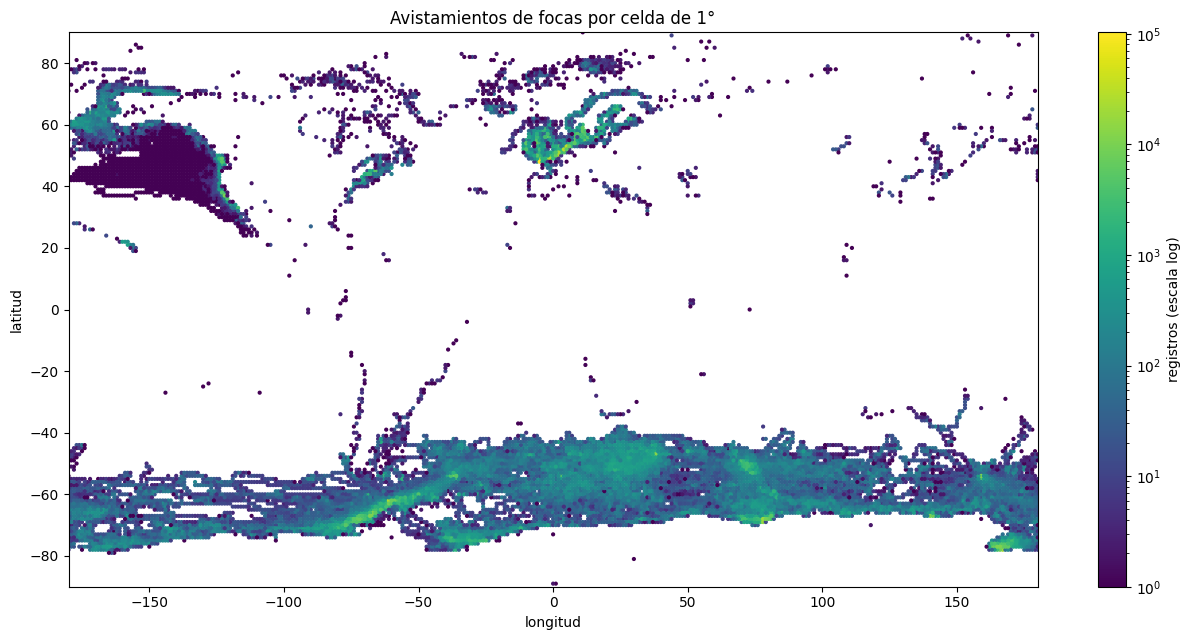

In [ ]:
import matplotlib.pyplot as plt

mapa = (validas.select(F.round("lat", 0).alias("lat"), F.round("lon", 0).alias("lon"))
               .groupBy("lat", "lon").count().toPandas())
fig, ax = plt.subplots(figsize=(13, 6.5))
sc = ax.scatter(mapa.lon, mapa.lat, c=mapa["count"], s=4, cmap="viridis", norm=plt.matplotlib.colors.LogNorm())
plt.colorbar(sc, label="registros (escala log)")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90)
ax.set_xlabel("longitud"); ax.set_ylabel("latitud")
ax.set_title("Avistamientos de focas por celda de 1°")
plt.tight_layout(); plt.show()

## 2.4 Selección de especies y construcción de características


Algunas especies tienen muy pocos registros, o estan extintas :(. Es debido a esto que el modelo solo considerara a las especies con al menos `Min_registros` (500) validos, las focas exlcuidas seguiran consideradas en el tablero, sin embargo no entrarian dentro del modelo.

A continuacion, se muestra una tabla con las caractersiticas, como se construye y por que


| Característica | Cómo se construye | Por qué |
|---|---|---|
| `x, y, z` | latitud/longitud convertidas a un punto sobre la esfera | evita el "salto" artificial entre longitud 180 y −180 |
| `lat`, `lon` | tal cual | los árboles cortan bien por rangos |
| `mes_sin`, `mes_cos` | mes como ángulo en un círculo | diciembre y enero quedan juntos (estacionalidad) |
| `year` | año del registro | cambios de distribución en el tiempo |
| `incert_log`, `sin_incert` | log de la incertidumbre de la ubicación y si falta | calidad de la coordenada |
| `conteo_log` | log del número de individuos | algunas especies se ven en colonias grandes |
| `pais` | `StringIndexer` + `OneHotEncoder` | contexto geográfico/político |
| `tipo_registro` | `StringIndexer` + `OneHotEncoder` | museo vs. observación vs. sensor |

En este caso se definen las especies de focas con mayor de 500 registros (15 especies) y se define la funcion preparar, la cual crea todas las caracteristicas de la tabla anterior. Esta funcion se utiliza para que exactamente las mismas transformaciones se apliquen a los datos de entrenamiento y mas adelante a los avistamientos nuevos que se quieran predecir.

In [ ]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler, StandardScaler, IndexToString
from pyspark.ml.functions import vector_to_array
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

MIN_REGISTROS = 500

conteo_especies = validas.groupBy("species").count()
especies_modelo = [r["species"] for r in conteo_especies.filter(F.col("count") >= MIN_REGISTROS)
                                                         .orderBy(F.desc("count")).collect()]
print(f"Especies en el modelo ({len(especies_modelo)}):", especies_modelo)

def preparar(df):
    rad_lat, rad_lon = F.radians("lat"), F.radians("lon")
    ang_mes = 2 * math.pi * F.col("month") / 12
    return (df
        .withColumn("x", F.cos(rad_lat) * F.cos(rad_lon))
        .withColumn("y", F.cos(rad_lat) * F.sin(rad_lon))
        .withColumn("z", F.sin(rad_lat))
        .withColumn("mes_sin", F.coalesce(F.sin(ang_mes), F.lit(0.0)))
        .withColumn("mes_cos", F.coalesce(F.cos(ang_mes), F.lit(0.0)))
        .withColumn("sin_mes", F.col("month").isNull().cast("double"))
        .withColumn("anio", F.col("year").cast("double"))
        .withColumn("incert_log", F.log1p(F.coalesce("incertidumbre", F.lit(0.0))))
        .withColumn("sin_incert", F.col("incertidumbre").isNull().cast("double"))
        .withColumn("conteo_log", F.log1p(F.greatest(F.coalesce("individualCount", F.lit(1)), F.lit(1)).cast("double")))
        .withColumn("pais", F.coalesce("countryCode", F.lit("ZZ")))
        .withColumn("tipo_registro", F.coalesce("basisOfRecord", F.lit("DESCONOCIDO"))))

datos = preparar(validas.filter(F.col("species").isin(especies_modelo)))

Especies en el modelo (15): ['Mirounga leonina', 'Leptonychotes weddellii', 'Halichoerus grypus', 'Phoca vitulina', 'Lobodon carcinophaga', 'Pusa hispida', 'Phoca largha', 'Erignathus barbatus', 'Mirounga angustirostris', 'Histriophoca fasciata', 'Hydrurga leptonyx', 'Neomonachus schauinslandi', 'Pagophilus groenlandicus', 'Ommatophoca rossii', 'Cystophora cristata']


El modeo se divide al azar en tran/val y test (70/15/15) y se anade que cada registro reciba un peso inversamente proporcional a su especie, en otras palabras las docas mas raras cuentan mas en los errores que las comunes, debido a que la foca gris y la foca comun cuentan con demasiados registros. Tambien se toma una muestra de ~400 mil registros de train para probar hiperparametros. Como se puede mostarr en lso resultados se muestan nuestras particiones.

In [ ]:
train, val, test = datos.randomSplit([0.70, 0.15, 0.15], seed=42)
train = train.repartition(16).cache(); val = val.cache(); test = test.cache()
n_train = train.count()
print(f"train={n_train:,}  val={val.count():,}  test={test.count():,}")

frec = {r["species"]: r["count"] for r in train.groupBy("species").count().collect()}
k = len(frec)
pesos = F.create_map(*[F.lit(x) for s, n in frec.items() for x in (s, n_train / (k * n))])
train = train.withColumn("peso", pesos[F.col("species")]).cache()

FRACCION_AJUSTE = min(1.0, 400_000 / n_train)
muestra_ajuste = train.sample(fraction=FRACCION_AJUSTE, seed=1).cache()
print(f"Muestra para ajuste: {muestra_ajuste.count():,} registros ({FRACCION_AJUSTE:.0%} de train)")

train=1,577,896  val=337,355  test=337,645
Muestra para ajuste: 398,974 registros (25% de train)


# Fase 3 · Modelado


## 3.1 Construcción del Pipeline de MLlib


En esta etapa se definen las etapas del pipeline, en donde se utiliza `StingIndexer` para conertir el texto en un numero, tambien se utiliza `StingIndexer` + `OneHotEncoder` para convertir los paises y tipos de registros en columnas de 0 y 1. `VectorAssembler`, el cual junta todas las caracteristicas en un solo vector, `StandardScaler` el cual las pone en un misma escala y finalmente `IndexToString` que como su nombre lo indica traduce la prediccion del numero a la especie.

Posteriormente, la funcion construir arma el pipeline completo con Rgeression Lineal o randomForest ambos obviamente utilizando la columa de pesos.

In [ ]:
idx_label = StringIndexer(inputCol="species", outputCol="label").fit(train)
CLASES = idx_label.labels
idx_cat = StringIndexer(inputCols=["pais", "tipo_registro"], outputCols=["pais_idx", "tipo_idx"],
                        handleInvalid="keep")
ohe = OneHotEncoder(inputCols=["pais_idx", "tipo_idx"], outputCols=["pais_ohe", "tipo_ohe"],
                    handleInvalid="keep", dropLast=False)
NUMERICAS = ["x", "y", "z", "lat", "lon", "mes_sin", "mes_cos", "sin_mes", "anio",
             "incert_log", "sin_incert", "conteo_log"]
ensamblador = VectorAssembler(inputCols=NUMERICAS + ["pais_ohe", "tipo_ohe"], outputCol="vec")
escalador = StandardScaler(inputCol="vec", outputCol="features", withMean=False, withStd=True)
a_texto = IndexToString(inputCol="prediction", outputCol="especie_pred", labels=CLASES)

def construir(nombre, params):
    if nombre == "Regresión logística":
        clf = LogisticRegression(featuresCol="features", labelCol="label", weightCol="peso",
                                 family="multinomial", maxIter=100, **params)
    else:
        clf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="peso",
                                     seed=42, **params)
    return Pipeline(stages=[idx_label, idx_cat, ohe, ensamblador, escalador, clf, a_texto])

def evaluador(m):
    return MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName=m)

## 3.2 Ajuste de hiperparámetros

Cada combinacion se entrena con la muestra de ajustes y se mide en val, con el proposito de encontrar los mejores hiperparametros y posteriormente solo la mejor de cada algoritmo se re entrena con todo el train. El conjunto de test sera solamente utilizado para el modelo final. Como se puede observar en el resultado el mejor modelo fue el RandomForest con 80 arboles y una profundidad de 14 teniendo un valor en accuracy_val de 0.8729 y un F1_Val de .8823 siendo mejor que todos los otros modelos, sin embargo es el modelo que mas tarda a comparacion de los demas.

In [ ]:
candidatos = {
    "Regresión logística": [{"regParam": 0.001}, {"regParam": 0.01}],
    "Random Forest": [{"numTrees": 50, "maxDepth": 10}, {"numTrees": 80, "maxDepth": 14}],
}

resultados, mejores = [], {}
for nombre, rejilla in candidatos.items():
    for params in rejilla:
        t0 = time.time()
        p = construir(nombre, params).fit(muestra_ajuste).transform(val)
        f1, acc = evaluador("f1").evaluate(p), evaluador("accuracy").evaluate(p)
        seg = time.time() - t0
        resultados.append({"modelo": nombre, "params": str(params), "f1_val": round(f1, 4),
                           "accuracy_val": round(acc, 4), "segundos": round(seg, 1)})
        print(f"{nombre:20s} {str(params):38s} f1_val={f1:.4f} acc_val={acc:.4f} ({seg:.0f}s)")
        if nombre not in mejores or f1 > mejores[nombre][0]:
            mejores[nombre] = (f1, params)

import pandas as pd
pd.DataFrame(resultados)

Regresión logística  {'regParam': 0.001}                    f1_val=0.6998 acc_val=0.6796 (175s)
Regresión logística  {'regParam': 0.01}                     f1_val=0.6463 acc_val=0.6231 (89s)
Random Forest        {'numTrees': 50, 'maxDepth': 10}       f1_val=0.8571 acc_val=0.8434 (161s)
Random Forest        {'numTrees': 80, 'maxDepth': 14}       f1_val=0.8823 acc_val=0.8729 (438s)


,modelo,params,f1_val,accuracy_val,segundos
0,Regresión logística,{'regParam': 0.001},0.6998,0.6796,175.2
1,Regresión logística,{'regParam': 0.01},0.6463,0.6231,89.4
2,Random Forest,"{'numTrees': 50, 'maxDepth': 10}",0.8571,0.8434,161.1
3,Random Forest,"{'numTrees': 80, 'maxDepth': 14}",0.8823,0.8729,437.7


## 3.3 Entrenamiento final

La configuracion de cada algoritmo se re entrena , pero ahora con toda la configuracion de todo el train (1.58 millones de datos), como se puede observar en el resultado la regression logistica tardo 7 minutos y el Random Forest tardo 22.9 minutos.

In [ ]:
modelos = {}
for nombre, (f1, params) in mejores.items():
    t0 = time.time()
    modelos[nombre] = construir(nombre, params).fit(train)
    print(f"{nombre}: reentrenado con todo train ({n_train:,} registros) en {(time.time() - t0) / 60:.1f} min")

Regresión logística: reentrenado con todo train (1,577,896 registros) en 7.0 min
Random Forest: reentrenado con todo train (1,577,896 registros) en 22.9 min


# Fase 4 · Evaluación


## 4.1 Métricas generales y línea base


Sobre el conjunto de test se calculan con MulticlassificationEvaluator, el accuraacy, el F1-score, la presicion, y el recall ponderados, y el log-loss. Posteriormente, estos resultados se comparan con una linea base, la cual es la exactitud que se obtendria si siempre se predijiera la especie mas comun, un modelo util debe superarla con claridad. Como se puede ver en el resultado la linea base (elefante marino sur) logra 46.2%. El Random Forest alcanza 86.8% de accuracy y F1 de 0.8787, siendo 40 puntos mas que la linea base y superando a la regression logistica, es debido a eso que el random forest es el modelo seleccionado.

In [ ]:
METRICAS = ["accuracy", "f1", "weightedPrecision", "weightedRecall", "logLoss"]
mas_comun = max(frec, key=frec.get)
linea_base = test.select(F.avg((F.col("species") == mas_comun).cast("double"))).first()[0]
print(f"Línea base (siempre '{mas_comun}'): accuracy = {linea_base:.4f}")

resumen_test, preds_test = [], {}
for nombre, modelo in modelos.items():
    p = (modelo.transform(test)
         .withColumn("confianza", F.array_max(vector_to_array("probability")))
         .cache())
    preds_test[nombre] = p
    fila = {"modelo": nombre, "params": str(mejores[nombre][1])}
    for m in METRICAS:
        fila[m] = evaluador(m).evaluate(p)
    fila["linea_base_accuracy"] = linea_base
    resumen_test.append(fila)

resumen_test = pd.DataFrame(resumen_test).round(4)
MEJOR = resumen_test.sort_values("f1", ascending=False).iloc[0]["modelo"]
modelo_final = modelos[MEJOR]
print("Modelo seleccionado:", MEJOR)
resumen_test

Línea base (siempre 'Mirounga leonina'): accuracy = 0.4616
Modelo seleccionado: Random Forest


,modelo,params,accuracy,f1,weightedPrecision,weightedRecall,logLoss,linea_base_accuracy
0,Regresión logística,{'regParam': 0.001},0.6798,0.7001,0.7924,0.6798,0.6910,0.4616
1,Random Forest,"{'numTrees': 80, 'maxDepth': 14}",0.8681,0.8787,0.9037,0.8681,0.4731,0.4616


## 4.2 Métricas por especie


En la tabla se puede mostrar las metricas por clase en donde el modelo nombro a cada especie, el soporte el cual es cuantas veces aparecio esa foca, el recall cuantas de esas focas el modelo pudo identificar, la presicion cuando le atina el modelo a la especie que en realidad era y finalmente el f1-score que es el primedio de presicion y recall. Lo que muestra es que las especies con habitat unico funcionan muy bien (foca monje Hawaii 1.0, elefante marino del sur 0.94 y Weddel 0.88), por otro lado las especies raras (foca leopardo, casco, Ross, Groenlandia) tienen un recall alto pero presicion baja, esto es debido a los pesos establecidos anteriormente y es por eso que el modelo prefiere predecirlas de mas antes que en lo que realidad aparece.

In [ ]:
def metricas_por_clase(p):
    reales = p.groupBy(F.col("species").alias("e")).agg(F.count("*").alias("soporte"))
    predichas = p.groupBy(F.col("especie_pred").alias("e")).agg(F.count("*").alias("predichas"))
    aciertos = (p.filter(F.col("species") == F.col("especie_pred"))
                 .groupBy(F.col("species").alias("e")).agg(F.count("*").alias("aciertos")))
    return (reales.join(predichas, "e", "left").join(aciertos, "e", "left").fillna(0)
            .withColumn("precision", F.col("aciertos") / F.greatest(F.col("predichas"), F.lit(1)))
            .withColumn("recall", F.col("aciertos") / F.col("soporte"))
            .withColumn("f1", F.when(F.col("precision") + F.col("recall") > 0,
                                     2 * F.col("precision") * F.col("recall") / (F.col("precision") + F.col("recall")))
                               .otherwise(0.0))
            .withColumnRenamed("e", "species")
            .withColumn("nombre", nombre_de("species"))
            .orderBy(F.desc("soporte")))

metricas_por_clase(preds_test[MEJOR]).select("nombre", "soporte", F.round("precision", 3).alias("precision"),
                                            F.round("recall", 3).alias("recall"), F.round("f1", 3).alias("f1")).show(30, truncate=False)

+-------------------------+-------+---------+------+-----+
|nombre                   |soporte|precision|recall|f1   |
+-------------------------+-------+---------+------+-----+
|Elefante marino del sur  |155860 |0.997    |0.883 |0.937|
|Foca de Weddell          |53171  |0.815    |0.943 |0.875|
|Foca gris                |51233  |0.96     |0.763 |0.85 |
|Foca común               |41981  |0.773    |0.84  |0.805|
|Foca cangrejera          |22241  |0.736    |0.92  |0.818|
|Foca anillada            |3711   |0.816    |0.82  |0.818|
|Foca manchada            |2725   |0.773    |0.532 |0.631|
|Foca barbuda             |2057   |0.711    |0.754 |0.732|
|Elefante marino del norte|1775   |0.337    |0.985 |0.503|
|Foca listada             |1167   |0.509    |0.933 |0.659|
|Foca leopardo            |734    |0.22     |0.966 |0.358|
|Foca monje de Hawái      |367    |1.0      |1.0   |1.0  |
|Foca de Groenlandia      |315    |0.088    |0.81  |0.158|
|Foca de Ross             |187    |0.114    |0.973 |0.20

## 4.3 Matriz de confusión


Spark cuenta cuantas veces cada especie real fue predicha como cada especie y solo esa tabla pequeña se pasa a pandas. Posteriormente cada fila se normaliza para que sume 100%. Como se puede observar en la figura la diagonal son los aciertos y lo que queda afuera de ella son las focas que confunde, de hecho como se puede observar las confusiones principales son entre las especies que comparten territorio, como es el caso de las focas de la antartida (Weddel, cangrejera, leopardo, ross)

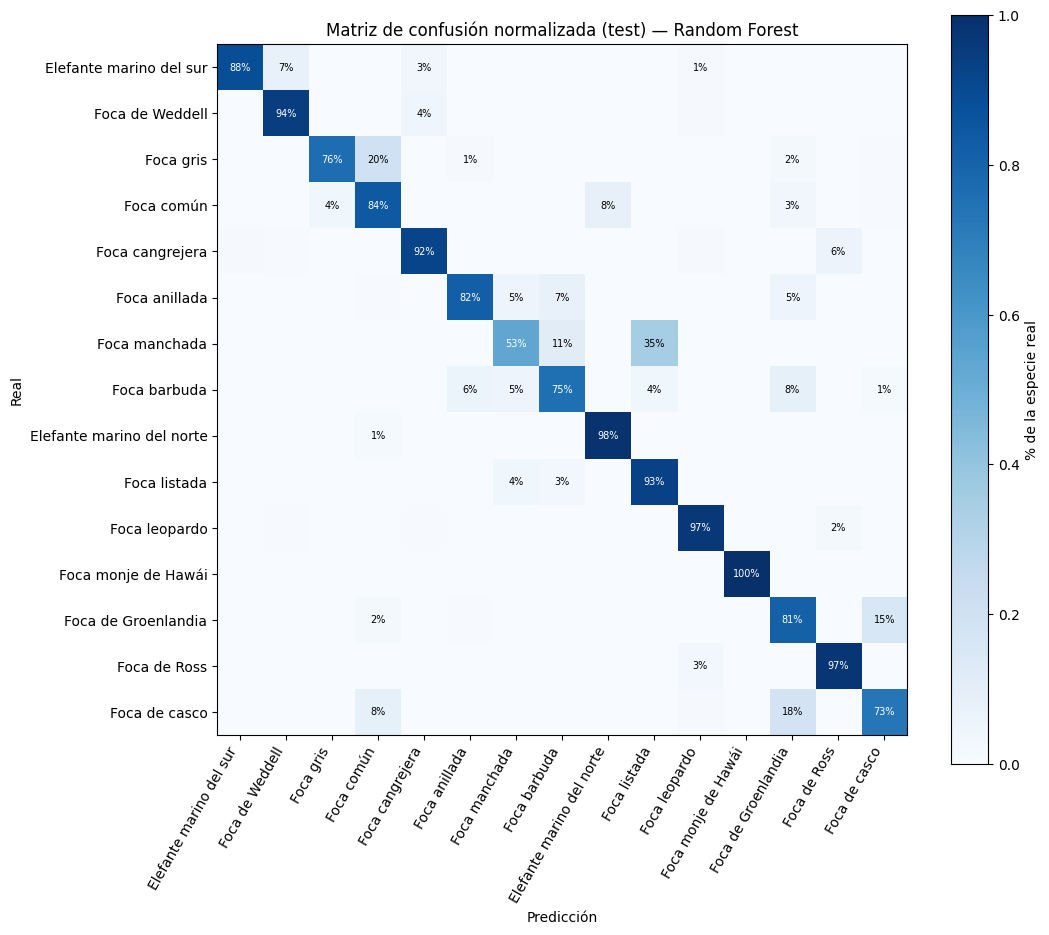

In [ ]:
import numpy as np

conf = (preds_test[MEJOR].groupBy("species", "especie_pred").count().toPandas()
        .pivot(index="species", columns="especie_pred", values="count")
        .reindex(index=CLASES, columns=CLASES).fillna(0))
conf_pct = conf.div(conf.sum(axis=1), axis=0)
etiquetas = [NOMBRES.get(c, c) for c in CLASES]

fig, ax = plt.subplots(figsize=(11, 9.5))
im = ax.imshow(conf_pct.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASES)), etiquetas, rotation=60, ha="right")
ax.set_yticks(range(len(CLASES)), etiquetas)
for i in range(len(CLASES)):
    for j in range(len(CLASES)):
        v = conf_pct.values[i, j]
        if v >= 0.01:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=7,
                    color="white" if v > 0.5 else "black")
plt.colorbar(im, label="% de la especie real")
ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusión normalizada (test) — {MEJOR}")
plt.tight_layout(); plt.show()

## 4.4 Importancia de las características


En esta seccion se suman todas las importancias de las columnas en un one-hot de un mismo grupo, por ejemplo todos los paises entrarian como solo pais y los nombres se obtienen de los metadatos que creo el `VectorAssembler`

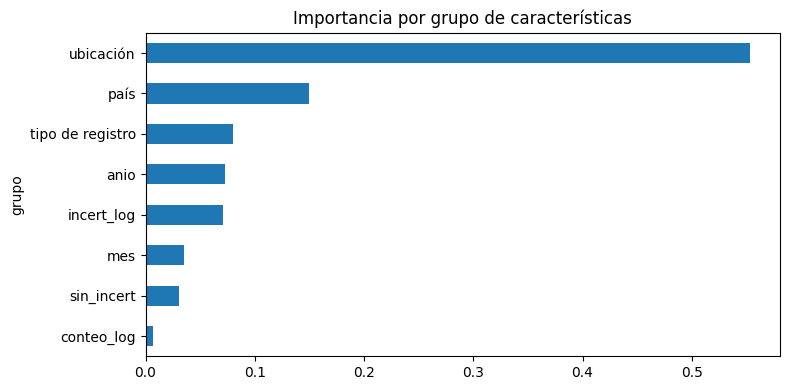

In [ ]:
rf = modelos["Random Forest"].stages[-2]
atributos = modelos["Random Forest"].transform(test.limit(1)).schema["vec"].metadata["ml_attr"]["attrs"]
nombres_vec = {a["idx"]: a["name"] for grupo in atributos.values() for a in grupo}

def grupo(n):
    if n.startswith("pais_ohe"): return "país"
    if n.startswith("tipo_ohe"): return "tipo de registro"
    if n in ("x", "y", "z", "lat", "lon"): return "ubicación"
    if n.startswith("mes") or n == "sin_mes": return "mes"
    return n

imp = (pd.DataFrame({"caracteristica": [nombres_vec[i] for i in range(len(nombres_vec))],
                     "importancia": rf.featureImportances.toArray()})
       .assign(grupo=lambda d: d["caracteristica"].map(grupo)))
imp_grupo = imp.groupby("grupo")["importancia"].sum().sort_values()
imp_grupo.plot.barh(figsize=(8, 4), title="Importancia por grupo de características"); plt.tight_layout(); plt.show()

## 4.5 Muestra de predicciones sobre test


Se eligen 15 registros al azar en el conjunto de test y se muestra la especie real, la prediccion, y la confianza del modelo. Como analizado en la parte anterior se muestra que el modelo se confunde con las focas que residen en el mismo territorio.

In [ ]:
(preds_test[MEJOR]
 .select(nombre_de("species").alias("real"), nombre_de("especie_pred").alias("prediccion"),
         F.round("confianza", 3).alias("confianza"), "lat", "lon", "year", "month", "countryCode")
 .orderBy(F.rand(seed=7)).limit(15).show(truncate=False))

+-----------------------+-------------------------+---------+----------+-----------+----+-----+-----------+
|real                   |prediccion               |confianza|lat       |lon        |year|month|countryCode|
+-----------------------+-------------------------+---------+----------+-----------+----+-----+-----------+
|Elefante marino del sur|Elefante marino del sur  |0.605    |-62.066073|-54.739171 |2010|12   |AQ         |
|Foca de Weddell        |Foca de Weddell          |0.603    |-67.665639|78.191946  |2006|3    |AQ         |
|Foca común             |Elefante marino del norte|0.825    |37.872097 |-122.308363|2023|4    |US         |
|Foca gris              |Foca de Groenlandia      |0.392    |42.366241 |-70.869075 |2026|6    |US         |
|Foca gris              |Foca gris                |0.856    |48.519    |-4.716     |2002|7    |FR         |
|Foca de Weddell        |Foca de Weddell          |0.763    |-74.697708|-33.784232 |2011|3    |AQ         |
|Foca cangrejera        |Foc

# Fase 5 · Despliegue


## 5.1 Predicción de avistamientos nuevos


En esta seccion se genera la funcion de predecir el cual recibe avistamientos hipoteticos con la ubicacion, fecha, pais,y tipo de registro. Gracias a esto devuelve las 3 especies mas probables, cabe mencionar que se usa exactamente el mismo pipeline que en el entrenamiento. Internamente crea un DataFrame de saprk con un esquema fijo, aplica preparar, y el modelo final, y ordena las probabilidades. Gracias a esto se obtiene el resultado de que en Hawaii acierta la foca monje con el 70%, en el Baltico la foca gris con el 57% y en Paises Bajos la foca comun con 62%. Finalmente en la Antartida, y el artico elige algunas especies raras de la zona (la foca greonlandia, leopardo), gracias a esto se clarifica los efectos de los pesos de clase vistos enteriormente.

In [ ]:
def predecir(avistamientos):
    filas = [{"lat": float(a["lat"]), "lon": float(a["lon"]), "month": a.get("mes"), "year": a.get("anio", 2024),
              "countryCode": a.get("pais"), "basisOfRecord": a.get("tipo", "HUMAN_OBSERVATION"),
              "incertidumbre": None, "individualCount": a.get("individuos", 1),
              "species": CLASES[0], "lugar": a.get("lugar", "")} for a in avistamientos]
    esquema = ("lat double, lon double, month int, year int, countryCode string, basisOfRecord string, "
               "incertidumbre double, individualCount int, species string, lugar string")
    df = spark.createDataFrame([tuple(f.values()) for f in filas], schema=esquema)
    res = modelo_final.transform(preparar(df)).select("lugar", vector_to_array("probability").alias("p")).toPandas()
    salida = []
    for _, fila in res.iterrows():
        top = np.argsort(fila.p)[::-1][:3]
        salida.append({"lugar": fila.lugar,
                       **{f"top{i + 1}": f"{NOMBRES.get(CLASES[j], CLASES[j])} ({fila.p[j]:.0%})" for i, j in enumerate(top)}})
    return pd.DataFrame(salida)

predecir([
    {"lugar": "Península Antártica, enero",  "lat": -64.8, "lon": -62.9, "mes": 1,  "pais": "AQ"},
    {"lugar": "Hawái, julio",                "lat": 21.3,  "lon": -157.8, "mes": 7, "pais": "US"},
    {"lugar": "Mar Báltico (Suecia), mayo",  "lat": 59.3,  "lon": 19.5,  "mes": 5,  "pais": "SE"},
    {"lugar": "Bahía de Monterey, marzo",    "lat": 36.6,  "lon": -121.9, "mes": 3, "pais": "US"},
    {"lugar": "Ártico de Canadá, abril",     "lat": 74.0,  "lon": -95.0, "mes": 4,  "pais": "CA"},
    {"lugar": "Países Bajos, agosto",        "lat": 53.2,  "lon": 4.9,   "mes": 8,  "pais": "NL"},
])

,lugar,top1,top2,top3
0,"Península Antártica, enero",Foca leopardo (54%),Foca cangrejera (22%),Elefante marino del sur (12%)
1,"Hawái, julio",Foca monje de Hawái (70%),Elefante marino del norte (9%),Elefante marino del sur (4%)
2,"Mar Báltico (Suecia), mayo",Foca gris (57%),Foca común (26%),Foca anillada (10%)
3,"Bahía de Monterey, marzo",Elefante marino del norte (84%),Foca común (9%),Foca de Groenlandia (3%)
4,"Ártico de Canadá, abril",Foca de Groenlandia (43%),Foca anillada (19%),Foca barbuda (15%)
5,"Países Bajos, agosto",Foca común (62%),Foca gris (25%),Foca de casco (8%)


## 5.2 Exportación de resultados para Tableau


Las agregaciones se hacen en Spark y solo las tablas finales se convierten a CSV. Para el mapa se exporta una rejilla de 1° y una muestra de puntos individuales.

| Archivo | Una fila por… | Uso en el tablero |
|---|---|---|
| `especies.csv` | especie | ranking, rango de años, países |
| `mapa_rejilla.csv` | especie × celda de 1° × década | mapa de distribución |
| `tendencia.csv` | especie × año × tipo de registro | registros en el tiempo |
| `registros_muestra.csv` | registro (muestra de hasta 300 mil) | mapa de puntos, filtros por mes |
| `metricas_especie.csv` | especie × modelo | F1 por especie |
| `resumen_modelos.csv` | modelo | KPIs |

In [ ]:
SALIDA = "/content/tableau"
os.makedirs(SALIDA, exist_ok=True)
def guardar(df, nombre):
    pdf = df.toPandas() if hasattr(df, "toPandas") else df
    pdf.to_csv(f"{SALIDA}/{nombre}", index=False)
    print(f"{nombre:24s} {len(pdf):>9,} filas")

guardar(validas.groupBy("species", "nombre").agg(
            F.count("*").alias("registros"), F.min("year").alias("primer_anio"), F.max("year").alias("ultimo_anio"),
            F.countDistinct("countryCode").alias("paises"), F.round(F.avg("lat"), 2).alias("lat_promedio"))
        .withColumn("en_modelo", F.col("species").isin(especies_modelo)), "especies.csv")
guardar(validas.groupBy("species", "nombre",
                        (F.floor(F.col("lat")) + 0.5).alias("lat_celda"), (F.floor(F.col("lon")) + 0.5).alias("lon_celda"),
                        (F.floor(F.col("year") / 10) * 10).cast("int").alias("decada"))
        .count().withColumnRenamed("count", "registros"), "mapa_rejilla.csv")
guardar(validas.groupBy("species", "nombre", "year", "basisOfRecord").count()
        .withColumnRenamed("count", "registros"), "tendencia.csv")
n_val = validas.count()
guardar(validas.sample(fraction=min(1.0, 300_000 / n_val), seed=3)
        .select("gbifID", "species", "nombre", "lat", "lon", "year", "month", "countryCode", "basisOfRecord",
                "individualCount", "institutionCode"), "registros_muestra.csv")

preds_pd, metr_pd, conf_pd = [], [], []
n_test = test.count()
for nombre, p in preds_test.items():
    preds_pd.append(p.sample(fraction=min(1.0, 150_000 / n_test), seed=5)
                     .select(F.lit(nombre).alias("modelo"), "gbifID", "lat", "lon", "year", "month", "countryCode",
                             nombre_de("species").alias("especie_real"), nombre_de("especie_pred").alias("especie_pred"),
                             F.round("confianza", 4).alias("confianza"),
                             (F.col("species") == F.col("especie_pred")).cast("int").alias("correcto")).toPandas())
    metr_pd.append(metricas_por_clase(p).withColumn("modelo", F.lit(nombre)).toPandas())
    conf_pd.append(p.groupBy(nombre_de("species").alias("especie_real"), nombre_de("especie_pred").alias("especie_pred"))
                    .count().withColumn("modelo", F.lit(nombre)).toPandas())
guardar(pd.concat(metr_pd).round(4), "metricas_especie.csv")

tiempos = pd.DataFrame(resultados).groupby("modelo")["segundos"].sum().rename("segundos_ajuste")
guardar(resumen_test.merge(tiempos, on="modelo").assign(seleccionado=lambda d: d["modelo"] == MEJOR)
        .assign(registros_crudos=n_crudo, registros_validos=n_val,
                gb_procesados=round(os.path.getsize(ARCHIVO) / 1024**3, 2)), "resumen_modelos.csv")

especies.csv                    21 filas
mapa_rejilla.csv            26,614 filas
tendencia.csv                2,278 filas
registros_muestra.csv      299,697 filas
metricas_especie.csv            30 filas
resumen_modelos.csv              2 filas


Posteriormente se se copian a GoogleDrive, se comprimen en Tableau_Focas.csv y se descarga en la computadora para poder ser cargados a TableauPublic

In [ ]:
from google.colab import drive, files
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/focas_spark && cp -r /content/tableau /content/drive/MyDrive/focas_spark/
!cd /content && zip -qr tableau_focas.zip tableau
files.download("/content/tableau_focas.zip")

Mounted at /content/drive


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 5.3 Tablero en Tableau Public


Link: https://public.tableau.com/app/profile/sebastian.perez5262/viz/BigDataAssignment_17939375584560/Dashboard1

Lo que presentan las graficas se puede observar en el siguiente texto:

1. **KPIs**: registros crudos → válidos, GB procesados, accuracy y F1 del modelo vs. línea base.
2. **Mapa de distribución**: `lon_celda`/`lat_celda` como coordenadas, color por `nombre`, tamaño por `registros`; filtro por `decada`.
3. **Ranking de especies**: barras horizontales de registros, coloreadas por `en_modelo`, tambien se muestran las barras excluidas e incluidas dentro del modelo separada por colores.
4. **Tendencia**: líneas de registros por año, color por `basisOfRecord`, muestra los avistamioentos de focas desde el 1950, y muestra el cambio de avistamientos.
5. **Estacionalidad**: mapa de calor especie × mes.
6. **Calidad del modelo**: Barras horizontales mostrando las especies de focas y su correlacion con el modelo (F1-score)

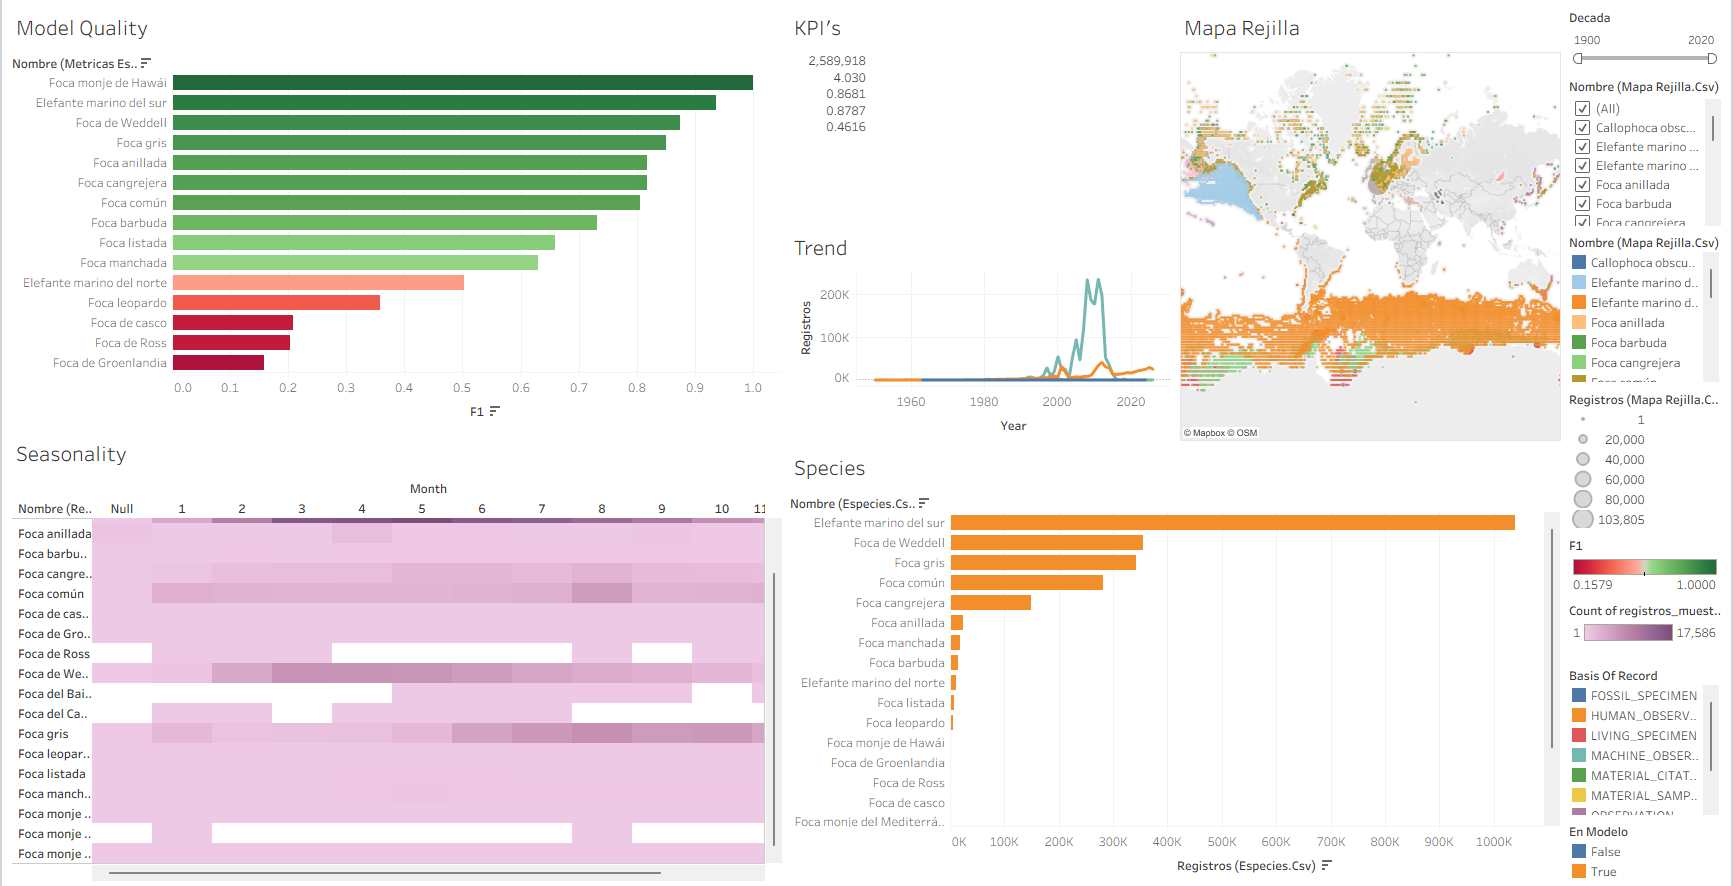

## Documentación del proceso y Conclusiones

## Resumen de lo realizado


1. **Ambiente:** Java 17 + PySpark 4.0.1 en Colab con una `SparkSession` local que usa todos los núcleos.
2. **Ingesta:** descarga directa del archivo Darwin Core de GBIF (familia Phocidae) y lectura distribuida del TSV completo con Spark.
3. **Almacenamiento:** conversión a Parquet con solo las columnas útiles y tipos correctos.
4. **Limpieza:** reglas de calidad y eliminación de duplicados con funciones de ventana.
5. **Exploración:** consultas con Spark SQL y un mapa de densidad agregado en Spark.
6. **Modelado:** `Pipeline` de MLlib con pesos de clase, comparando Regresión logística y Random Forest.
7. **Evaluación:** `MulticlassClassificationEvaluator` en test, comparación contra línea base, métricas por especie, matriz de confusión e importancia de características.
8. **Predicción:** función `predecir` que devuelve las 3 especies más probables para avistamientos nuevos.
9. **Visualización:** Dashboard de Tableau public.

## Decisiones para procesar el volumen de datos de forma eficiente
| Técnica | Por qué |
|---|---|
| Descarga directa a `/content` con `wget` | evita subir varios GB a Drive y leer desde Drive, que es lento y costoso |
| `maxPartitionBytes = 128 MB` | el archivo se lee en bloques paralelos |
| Sin `inferSchema` | evita una segunda lectura completa del archivo |
| Parquet con columnas seleccionadas | el texto de 4.0GB se lee una sola vez y queda en 71 MB, siendo mucho mas pequeño |
| `cache()` de los DataFrames reutilizados | no se recalcula la limpieza en cada consulta |
| Funciones de ventana para duplicados | se resuelve en paralelo sin traer datos al driver |
| Ajuste de hiperparámetros con una muestra | se prueban varias configuraciones|

## Resultados
| Etapa | Resultado |
|---|---|
| Datos procesados | `occurrence.txt` de **4.03 GB**, **2,589,918 registros**, 230 columnas |
| Lectura | 33 particiones, conteo completo en 17 s |
| Parquet | 17 columnas, **71 MB**, escrito en 1.2 min |
| Limpieza | **2,253,505 registros válidos (87 %)**; 208,847 duplicados eliminados |
| Especies en el modelo | 15 (con ≥ 500 registros) |
| Mejor modelo | Random Forest, 80 árboles, profundidad 14 |
| Test | **accuracy 0.868 · F1 0.879 · logLoss 0.473** vs. línea base 0.462 |
| Mejores especies | foca monje de Hawái (F1 1.00), elefante marino del sur (0.94), Weddell (0.88) |
| Especies difíciles | Groenlandia (0.16), Ross (0.20), casco (0.21), leopardo (0.36) |

## Conclusiones

Gracias a este trabajo pude aprender mas sobre las herramientas de Spark, de hecho gracias a Spark me permitio procesar 4GB y 2.6 millones de datos en un entrono de solo 2 nucleos, por otro lado la conversion a Parquet ayudo debido a que redujo el tamaño un ~98%, lo cual acelero el flujo del proyecto. Por otra parte, se identifico que el RandomForest identifica el 87% de las especies, lo cual es casi el doble de lo analizado en la linea base. Gracias a esto podemos concluir, que el modelo es confiable solo para las especies con habitat propio, ya que las que comparten territorio llega a cometer errroes.